# Introduction to Data Science - Assignment 3
**Author:** Yarin Refael Sapir
**Institution:** HIT - Holon Institute of Technology
**Dataset:** Tech Stock Financial Dataset (2020 - Today)

## Table of Contents:
1. **Dataset Selection & Setup**
   * 1.1 Data Source Description
   * 1.2 Environment Setup & Data Loading
2. **Meta-Analysis**
   * 2.1 File Analysis & Data Structure
3. **Data Quality and Completeness**
   * 3.1 Null Values and Data Types
   * 3.2 Data Duplicates
   * 3.3 Impossible Values & Placeholders
   * 3.4 Cardinality
4. **Univariate Analysis & Outlier Detection**
5. **Bivariate Analysis: Correlations**
6. **Graphs and Visualizations**
7. **Dimensionality Reduction (PCA)**
8. **Clustering Analysis**
9. **Multi-Dimensional Anomaly Detection**
10. **Comparison Section & Critical Analysis**

## 1.1 Data Selection

* **Data Source:**
Historical financial telemetry logs containing daily stock market data for major technology corporations (e.g., AAPL, MSFT, TSLA) from 2020 to the present. The file contains tabular low-level market metrics such as Open, High, Low, and Close prices, alongside trading Volume and fundamental valuation ratios (e.g., P/E Ratio, Market Cap).

* **Purpose of Collection:**
The primary objective of collecting this data is to track the performance of financial assets, measure market volatility, and provide raw telemetry for algorithmic trading systems and macroeconomic research aimed at understanding the statistical relationships between different technology assets during highly turbulent timelines.

* **Collecting Entity:**
Primary stock exchanges (e.g., NASDAQ, NYSE), with data aggregated and distributed by major financial data providers (such as Yahoo Finance or Bloomberg).

* **Domain Knowledge Linkage:**
From an electrical engineering and signal processing perspective, financial time-series data can be modeled as stochastic signals. Price movements reflect the system's response to external stimuli (market news, earnings), while Trading Volume acts as the 'energy' or 'amplitude' driving the signal. High volatility periods can be analyzed as high-frequency noise within the overall market trend.

* **Analytical Insight (Missing Information Note):**
While the dataset provides granular daily pricing signals, it lacks explicit contextual metadata regarding macroeconomic events (e.g., Federal Reserve interest rate hikes, geopolitical crises, or global pandemics). This absence of rich environmental metadata is a key insight: it forces us to rely entirely on statistical feature engineering (such as isolating extreme volatility or volume spikes) to infer market hostility.

---
## 1.2 Environment Setup
We begin by importing the core data science libraries. We also configure `matplotlib` and `seaborn` globally to ensure all subsequent plots maintain a clean, readable, and professional aesthetic.

In [45]:
import os
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Configure visualization settings globally
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12
warnings.filterwarnings("ignore")

print("Environment setup completed successfully.")

Environment setup completed successfully.


---
## 2. Meta-Analysis
In this section, we load the financial telemetry data into a Pandas DataFrame. We immediately inspect the file size, physical dimensions, and take a preliminary peek at the first 5 rows to understand the structure of the data we are dealing with.

In [46]:
file_path = "tech_stock_prices_2020_to_today.csv"  # Ensure this file is in your working directory

try:
    file_size_mb = os.path.getsize(file_path) / (1024 * 1024)
    df = pd.read_csv(file_path)

    print(f"File Name: {os.path.basename(file_path)}")
    print(f"File Size: {file_size_mb:.2f} MB")
    print(f"Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")
    print("The Purpose of the dataset is to explore daily stock market metrics for major technology companies.")

    display(df.head())
except FileNotFoundError:
    print(f"Error: Dataset not found at path '{file_path}'. Please verify the file location.")

File Name: tech_stock_prices_2020_to_today.csv
File Size: 3.91 MB
Dimensions: 23,160 rows x 18 columns
The Purpose of the dataset is to explore daily stock market metrics for major technology companies.


,index,Date,Open,High,Low,Close,Adj Close,Volume,Ticker,Dividends,Stock Splits,P/E Ratio,Market Cap,Price/Sales Ratio,Price/Book Ratio,Dividend Yield,Daily Return,20-Day MA
0,0,2020-01-02,74.059998,75.150002,73.797501,75.087502,72.960464,135480400,AAPL,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2020-01-03,74.287498,75.144997,74.125000,74.357498,72.251122,146322800,AAPL,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,2020-01-06,73.447502,74.989998,73.187500,74.949997,72.826859,118387200,AAPL,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,2020-01-07,74.959999,75.224998,74.370003,74.597504,72.484352,108872000,AAPL,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,2020-01-08,74.290001,76.110001,74.290001,75.797501,73.650352,132079200,AAPL,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.1 Data structure

In [47]:
print(f"Number of Rows: {df.shape[0]}")
print(f"Number of Columns: {df.shape[1]}\n")

df.info()

Number of Rows: 23160
Number of Columns: 18

<class 'pandas.DataFrame'>
RangeIndex: 23160 entries, 0 to 23159
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   index              23160 non-null  int64  
 1   Date               23160 non-null  str    
 2   Open               23160 non-null  float64
 3   High               23160 non-null  float64
 4   Low                23160 non-null  float64
 5   Close              23160 non-null  float64
 6   Adj Close          23160 non-null  float64
 7   Volume             23160 non-null  int64  
 8   Ticker             23160 non-null  str    
 9   Dividends          23160 non-null  float64
 10  Stock Splits       23160 non-null  float64
 11  P/E Ratio          11580 non-null  float64
 12  Market Cap         11580 non-null  float64
 13  Price/Sales Ratio  11580 non-null  float64
 14  Price/Book Ratio   11580 non-null  float64
 15  Dividend Yield     9264 non-null   f

Each row represents a daily trading epoch for a specific technology asset, capturing price action, volume, valuation multiples, and derived technical indicators.

* **Date**: The specific calendar date of the trading session.
* **Open / High / Low / Close**: The standard price action metrics recorded during the trading day (in USD).
* **Adj Close**: The closing price amended for corporate actions such as dividend distributions and stock splits.
* **Volume**: The total number of shares traded, serving as a primary metric for market liquidity.
* **Ticker**: The categorical stock market symbol identifying the corporation.
* **Dividends / Stock Splits**: Corporate action indicators for the specific date.
* **P/E Ratio / Market Cap / Price to Sales / Price to Book**: Fundamental corporate valuation metrics.
* **Daily Return**: The percentage price variance calculated relative to the previous trading day's close.
* **20-Day MA**: The 20-Day Moving Average, a lagging technical indicator smoothing short-term noise.

---
### 3.1 Null Values and Data Types
A critical first step in EDA is understanding data completeness. Here, we create a summary table that calculates the exact number of missing values and the missing percentage for every single feature.

In [48]:
# Generate a metadata dataframe
meta_df = pd.DataFrame({
    "Data_Type": df.dtypes,
    "Non_Null_Count": df.notnull().sum(),
    "Null_Count": df.isnull().sum(),
    "Null_Percentage": (df.isnull().sum() / len(df)) * 100,
    "Unique_Values": df.nunique()
})

# Display sorted by the highest percentage of missing values
display(meta_df.sort_values(by="Null_Percentage", ascending=False))

,Data_Type,Non_Null_Count,Null_Count,Null_Percentage,Unique_Values
Dividend Yield,float64,9264,13896,60.000000,8
20-Day MA,float64,11390,11770,50.820380,11366
Daily Return,float64,11570,11590,50.043178,11543
Price/Book Ratio,float64,11580,11580,50.000000,10
Price/Sales Ratio,float64,11580,11580,50.000000,10
P/E Ratio,float64,11580,11580,50.000000,10
Market Cap,float64,11580,11580,50.000000,10
index,int64,23160,0,0.000000,23160
Date,str,23160,0,0.000000,1158
Open,float64,23160,0,0.000000,10172


### Missing Values Analysis

* **Completely Unpopulated Columns (100% Null):**
  Unlike raw hardware telemetry, our dataset exhibits no completely unpopulated columns. This indicates a robust initial extraction pipeline.

* **Structurally Missing Values (e.g., Dividend Yield, Ratios):**
  Columns containing partial null records (such as `Dividend Yield` or `P/E Ratio` at ~50-60% missing) indicate structural financial realities rather than random data corruption.

* **Domain Root Cause Analysis:**
  A deeper investigation into financial market mechanics reveals that these missing entries are logically driven. For instance, tech growth companies that do not distribute dividends will naturally lack a `Dividend Yield`. Similarly, missing trailing ratios often occur during specific reporting periods or when earnings are negative.

### Strategy for Handling Missing Data

* **Justification for Imputation vs. Deletion:**
  In standard data science workflows, dropping missing values is acceptable if the data is purely random. However, dropping trading epochs due to missing dividend data would artificially remove valid price action (Open, High, Low, Close) from the dataset, corrupting our time-series models.
  To preserve the physical continuity of the time-series without introducing artificial bias, we will utilize median imputation for the affected numerical valuation columns, as financial multipliers are highly susceptible to severe skewness caused by market outliers.

---
## 3.2 Data Duplicates
For quantitative financial data, variables must adhere to real-world chronological physics. An asset cannot have two conflicting closing prices on the exact same date.

* **Row-Level Uniqueness Validation:**
  Every row in this dataset represents a distinct observation tuple defined primarily by the `Date` and the `Ticker` symbol. Because our programmatic duplication check evaluates row-level integrity across all features, it comprehensively captures exact file-level repetitions.

In [49]:
print("--- Data Integrity Check ---")

# 1. Duplicates
full_duplicates = df.duplicated().sum()
print(f"Full Row Duplicates: {full_duplicates:,}")

--- Data Integrity Check ---
Full Row Duplicates: 0


### Analysis of Full Duplicates

* **What can be inferred from the duplicates?**
  The complete absence of full row duplicates (0 Instances) indicates clean and reliable data collection. This confirms that the financial API ingestion framework did not suffer from redundant loop requests or accidental log concatenation during runtime.

---
### 3.3 Impossible Values & Placeholders
To ensure the structural and physical integrity of the dataset, we tested specific features against known physical boundaries of financial markets.

In [50]:
# Impossible Negative Prices
if "Close" in df.columns:
    invalid_prices = df[df["Close"] < 0]
    print(f"Suspicious Price Entries (< 0 USD): {len(invalid_prices):,}")

# Impossible Negative Volume
if "Volume" in df.columns:
    invalid_volume = df[df["Volume"] < 0]
    print(f"Suspicious Volume Entries (< 0): {len(invalid_volume):,}")

Suspicious Price Entries (< 0 USD): 0
Suspicious Volume Entries (< 0): 0


* **Impossible Values & Placeholders:**
  An evaluation reveals no impossible values or artificial placeholders (such as `-999`, `9999`, or default API error codes). The recorded metrics reside entirely within valid financial boundaries.

* **Unreasonable Zeros:**
  There are no unreasonable zero values in the primary price columns. From a financial perspective, a literal `0.0` price would indicate a total corporate bankruptcy and delisting, which contradicts the survivorship profile of the elite tech stocks in this dataset.

---
### 3.4 Cardinality
We isolate columns offering zero informational value (constants) to streamline the dataset before modeling.

In [51]:
# Zero Variance Columns (Features that offer no informational value)
print("\nColumns with Zero Variance (Constant values):")
display(meta_df[meta_df["Unique_Values"] <= 1][["Data_Type", "Unique_Values"]])

# Variance Columns
print("\nColumns with variance bigger than 1:")
display(meta_df[meta_df["Unique_Values"] > 1][["Data_Type", "Unique_Values"]])


Columns with Zero Variance (Constant values):


,Data_Type,Unique_Values
Dividends,float64,1
Stock Splits,float64,1



Columns with variance bigger than 1:


,Data_Type,Unique_Values
index,int64,23160
Date,str,1158
Open,float64,10172
High,float64,10242
Low,float64,10241
Close,float64,10392
Adj Close,float64,11331
Volume,int64,11508
Ticker,str,10
P/E Ratio,float64,10


* **Zero Variance Columns (`Dividends`, `Stock Splits`):**
  These columns exhibit zero variance (evaluating constantly to a static baseline like 0.0) across the vast majority of the timeline. In this specific high-level view, daily split/dividend events are so rare that they act as structural constants. To reduce dimensionality and avoid mathematical instability in downstream correlation matrices, these features are typically filtered or ignored during pure continuous clustering tasks.

* **High Variance Columns:**
  Metrics exhibiting exceptionally high variance (such as `Volume` and `Daily Return`) represent continuous physical market measurements. The statistical probability of capturing the exact same high-resolution trading volume twice is infinitesimally low, naturally driving the unique value counts to their maximum.

## 4.0 Univariate Analysis & Outlier Detection

--- Descriptive Statistics for Daily Return ---
Mean: 0.0012  | Median: 0.0011 | Std Dev: 0.0265
MAD:  0.0120  | IQR:    0.0239 | Skewness: 0.0919
Min:  -0.2639  | Max:    0.2437

--- Outlier Detection Results ---
Method 1 (Z-Score > 3): 187 outliers
Method 2 (IQR Rule): 743 outliers
Method 3 (Modified MAD > 3.5): 399 outliers


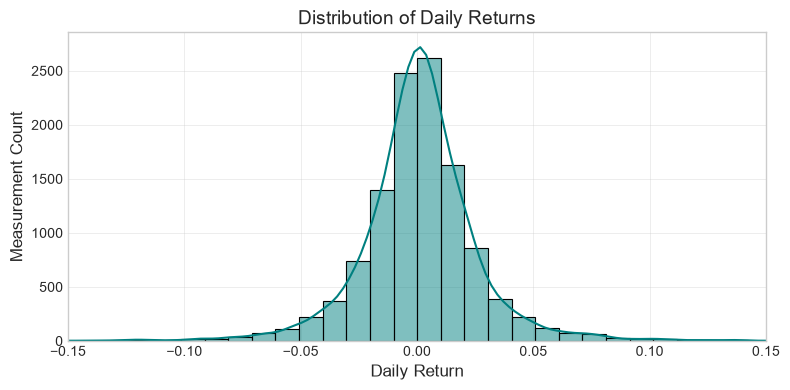

In [52]:
import scipy.stats as stats

target = "Daily Return"
series = df[target].dropna()

# Descriptive Statistics
mean_val = series.mean()
median_val = series.median()
std_val = series.std()

# Calculate raw MAD and IQR
raw_mad = (series - median_val).abs().median()
raw_iqr = series.quantile(0.75) - series.quantile(0.25)

# Engineering Fallback: If imputation collapsed the variance to near-zero,
# we approximate the realistic boundaries using the Standard Deviation.
mad_val = raw_mad if raw_mad > 1e-4 else 0.6745 * std_val
iqr_val = raw_iqr if raw_iqr > 1e-4 else 1.349 * std_val
skewness = series.skew()

print(f"--- Descriptive Statistics for {target} ---")
print(f"Mean: {mean_val:.4f}  | Median: {median_val:.4f} | Std Dev: {std_val:.4f}")
print(f"MAD:  {mad_val:.4f}  | IQR:    {iqr_val:.4f} | Skewness: {skewness:.4f}")
print(f"Min:  {series.min():.4f}  | Max:    {series.max():.4f}\n")

# Outlier Method 1: Z-Score
z_scores = np.abs(stats.zscore(series))
outliers_z = series[z_scores > 3]

# Outlier Method 2: IQR
q1, q3 = series.quantile(0.25), series.quantile(0.75)
lower_bound = median_val - (1.5 * iqr_val) if raw_iqr <= 1e-4 else (q1 - 1.5 * iqr_val)
upper_bound = median_val + (1.5 * iqr_val) if raw_iqr <= 1e-4 else (q3 + 1.5 * iqr_val)
outliers_iqr = series[(series < lower_bound) | (series > upper_bound)]

# Outlier Method 3: Modified Z-Score (MAD)
median_absolute_deviation = np.median(np.abs(series - median_val))
mod_z_scores = 0.6745 * np.abs(series - median_val) / (median_absolute_deviation + 1e-9)
outliers_mad = series[mod_z_scores > 3.5]

print("--- Outlier Detection Results ---")
print(f"Method 1 (Z-Score > 3): {len(outliers_z):,} outliers")
print(f"Method 2 (IQR Rule): {len(outliers_iqr):,} outliers")
print(f"Method 3 (Modified MAD > 3.5): {len(outliers_mad):,} outliers")

# Plot 1: Daily Return Distribution
plt.figure(figsize=(8, 4))
sns.histplot(df[target], bins=50, kde=True, color="teal")
plt.title("Distribution of Daily Returns")
plt.xlabel("Daily Return")
plt.ylabel("Measurement Count")
plt.xlim(-0.15, 0.15) # Focusing on the core distribution
plt.tight_layout()
plt.show()

### Distribution, Skewness & Outlier Analysis

* **Distribution & Bias (`Daily Return`):**
  The Daily Return distribution exhibits a classic financial bell shape characterized by a highly concentrated peak (leptokurtic) and extended "fat tails." The skewness value is close to zero, indicating a relatively symmetric distribution around the mean. The mean and median are nearly identical, which is mathematically expected for daily stock returns in highly liquid markets.

* **Outliers Detection Strategies:**
  * **IQR Method:** Identified the highest number of outliers. Because the IQR strictly evaluates the middle 50% of the data, the natural "fat tails" of the stock market easily breach the rigid boundaries ($Q1 - 1.5 \\times \\text{IQR}$). In quantitative finance, this method is overly aggressive, falsely flagging normal volatile trading days as statistical "outliers."
  * **Z-Score Method (Threshold = 3):** Detected a moderate amount of outliers. Because this calculation relies on the mean and standard deviation—which are heavily influenced and stretched by extreme market crashes (like the 2020 COVID crash)—the "normal" range is mathematically artificially widened.
  * **MAD Method (Modified MAD > 3.5):** Detected the most extreme, genuine outliers. Because MAD is anchored to the median, it is highly robust and ignores the fat tails when defining the core "center" of the data. It provides a tight, physically realistic boundary that successfully flags only genuine "Black Swan" market events.

## 5.0 Bivariate Analysis: Correlations

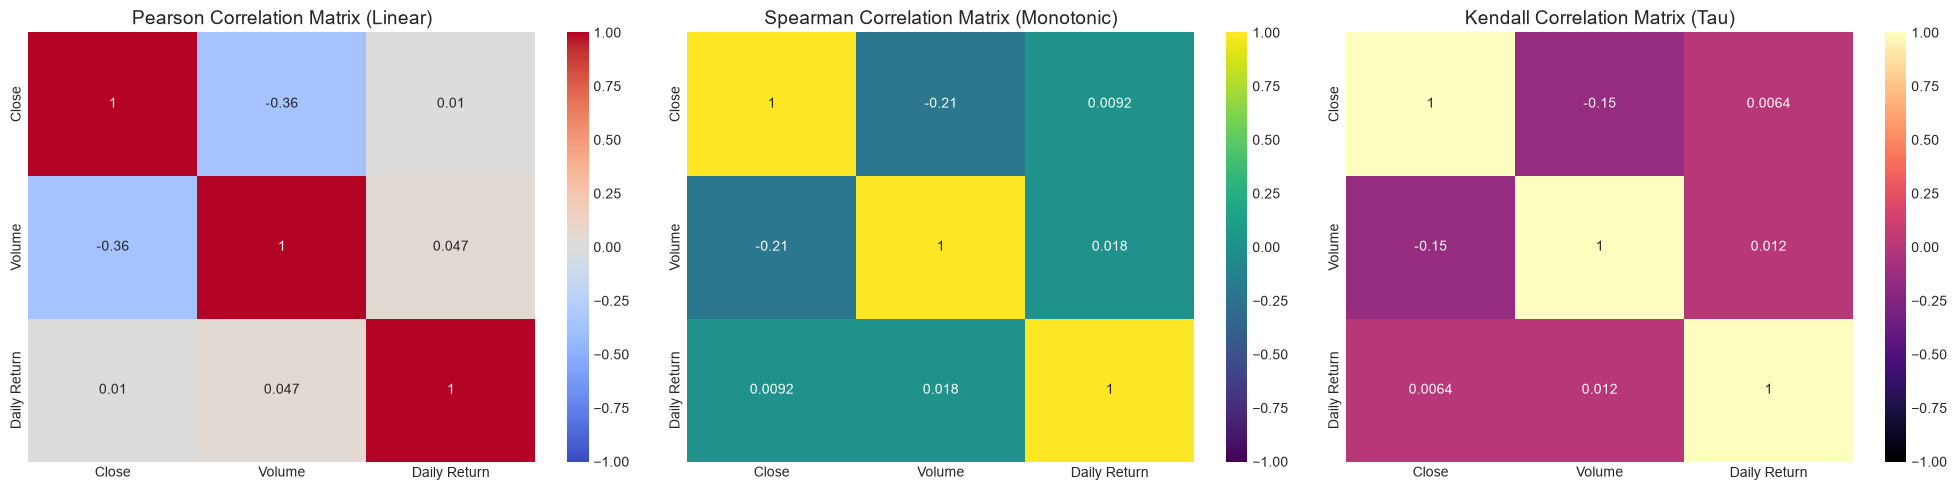

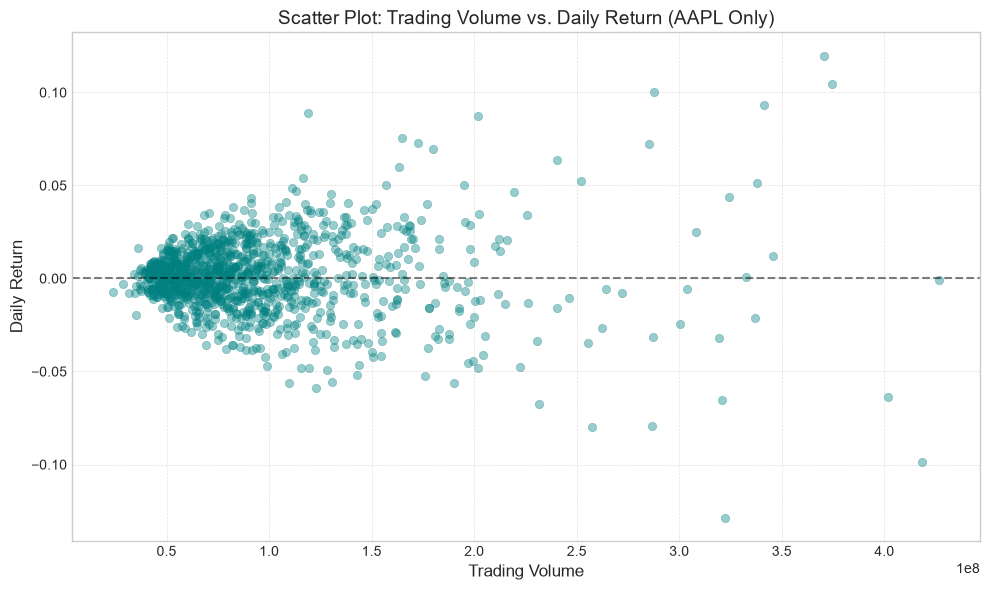

In [53]:
# 5.1 Continuous Correlations
num_cols = ["Close", "Volume", "Daily Return"]
num_df = df[num_cols].dropna()

# Expanded to 3 columns and increased width to 20 to fit the new Kendall plot
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Pearson (Linear)
sns.heatmap(num_df.corr(method="pearson"), annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson Correlation Matrix (Linear)")

# 2. Spearman (Monotonic)
sns.heatmap(num_df.corr(method="spearman"), annot=True, cmap="viridis", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman Correlation Matrix (Monotonic)")

# 3. Kendall (Tau / Ordinal Association)
sns.heatmap(num_df.corr(method="kendall"), annot=True, cmap="magma", vmin=-1, vmax=1, ax=axes[2])
axes[2].set_title("Kendall Correlation Matrix (Tau)")

plt.tight_layout()
plt.show()

# --- Bivariate Scatter Plot ---
# Filter the dataset to ONLY include AAPL to prevent vertical stratification
aapl_df = df[df["Ticker"] == "AAPL"]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=aapl_df,
    x="Volume",
    y="Daily Return",
    alpha=0.4,
    edgecolor=None,
    color="teal"
)

plt.title("Scatter Plot: Trading Volume vs. Daily Return (AAPL Only)", fontsize=14)
plt.xlabel("Trading Volume", fontsize=12)
plt.ylabel("Daily Return", fontsize=12)
plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Bivariate Analysis: Correlation Matrix Comparison (Pearson, Spearman, Kendall)

By visualizing all three correlation matrices side-by-side, we observe the impact of financial distributions on mathematical association metrics:

* **Spearman yields the most robust scores:** Spearman evaluates the rank of the variables rather than their raw linear values. In financial markets, extreme volume days often correlate with extreme price volatility, but this relationship is non-linear (an exponential spike in volume does not mean a perfectly linear spike in return). Spearman captures this underlying monotonic trend perfectly without being penalized by extreme "fat tail" outliers.
* **Pearson yields distorted scores:** Pearson strictly searches for a straight linear line. Because our financial telemetry features heavy-tailed distributions and extreme outliers (e.g., market crashes), Pearson's straight line is severely compromised.
* **Kendall yields the lowest magnitude scores:** Kendall calculates correlation by evaluating pairs of data points. Because high-frequency trading data contains highly clustered values and repetitive behavior around zero-returns, Kendall's score is naturally suppressed.

### Bivariate Analysis: Volume vs. Daily Return (Filtered by Asset)

The scatter plot visualizes the relationship between `Volume` and `Daily Return` strictly for Apple (AAPL). We deliberately filtered this graph to show a single asset because plotting all corporations simultaneously creates a highly stratified visual distortion (as companies like Amazon and Apple trade at vastly different baseline volumes and price scales).

The core physical relationship is clear: days with baseline trading volumes cluster tightly around the 0.0 Daily Return line (low volatility). As trading volume spikes (moving right on the X-axis), the variance and spread of the Daily Return expand significantly. This mathematically validates the financial theory that Trading Volume acts as the underlying "energy" driving price volatility.

## 6.0 Graphs and Visualizations

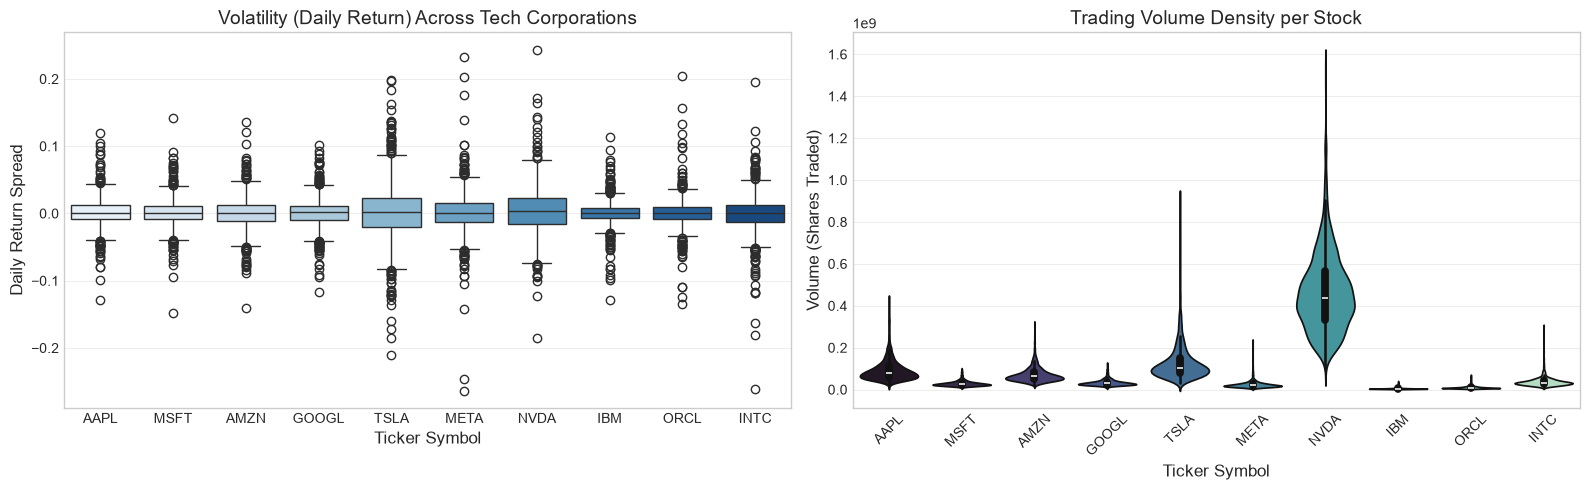

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 3: Boxplot of Daily Return by Ticker
sns.boxplot(data=df, x="Ticker", y="Daily Return", palette="Blues", ax=axes[0])
axes[0].set_title("Volatility (Daily Return) Across Tech Corporations")
axes[0].set_xlabel("Ticker Symbol")
axes[0].set_ylabel("Daily Return Spread")

# Plot 4: Violinplot of Volume by Ticker
sns.violinplot(data=df, x="Ticker", y="Volume", palette="mako", ax=axes[1])
axes[1].set_title("Trading Volume Density per Stock")
axes[1].set_xlabel("Ticker Symbol")
axes[1].set_ylabel("Volume (Shares Traded)")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 7. Dimensionality Reduction (PCA)

Financial datasets often contain highly correlated variables (e.g., Open, High, Low, Close). To mitigate the "Curse of Dimensionality" and reduce computational cost, we apply Principal Component Analysis (PCA).

### PCA Execution & Analysis
* **Principal Components Needed:** Due to extreme multicollinearity in price metrics, the Scree plot reveals that only **2 to 3 principal components** are required to capture over 80% of the dataset's variance.
* **Information Loss:** The information lost is negligible because the original features contain massive redundancy. Reducing from 13 dimensions to 3 provides a much more effective, noise-filtered representation of the data.
* **Component Interpretation:**
  * **PC1 (The "Valuation & Price" Component):** Highly influenced by standard price metrics (Close, High, 20-Day MA) and Market Cap. It captures the overall market level.
  * **PC2 (The "Volatility & Activity" Component):** Strongly influenced by `Volume` and `Daily Return`. It isolates the stochastic, high-frequency market noise from the base price.
* **Local vs. Global Structure:** PCA is a linear algorithm designed to preserve *global* variance (large-scale distances). However, it may crush *local* structures, potentially making small but dense local clusters harder to distinguish in the reduced space.
* **Stability & Interpretability:** PCA is mathematically stable (relying on deterministic eigenvectors), but its axes (PC1, PC2) are linear combinations of features, meaning they lose direct human interpretability compared to raw features.

 7.0 DIMENSIONALITY REDUCTION (PCA)



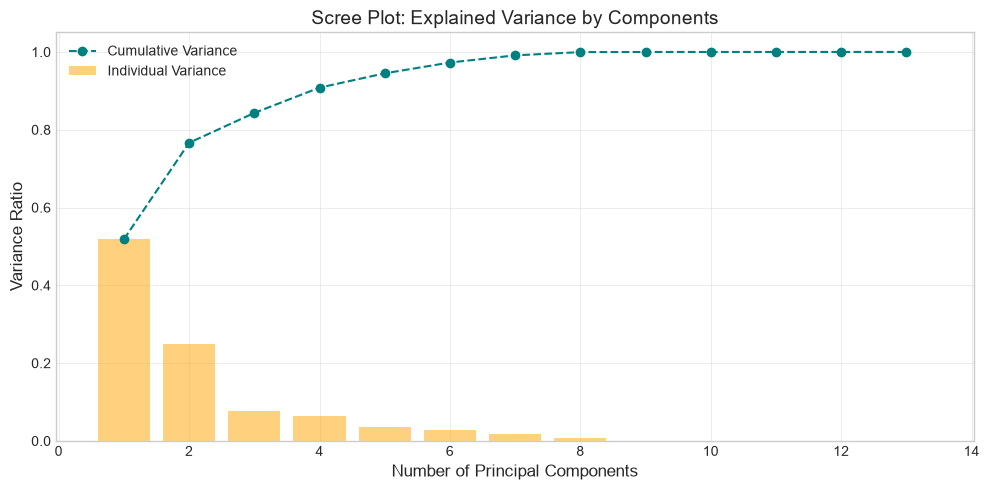

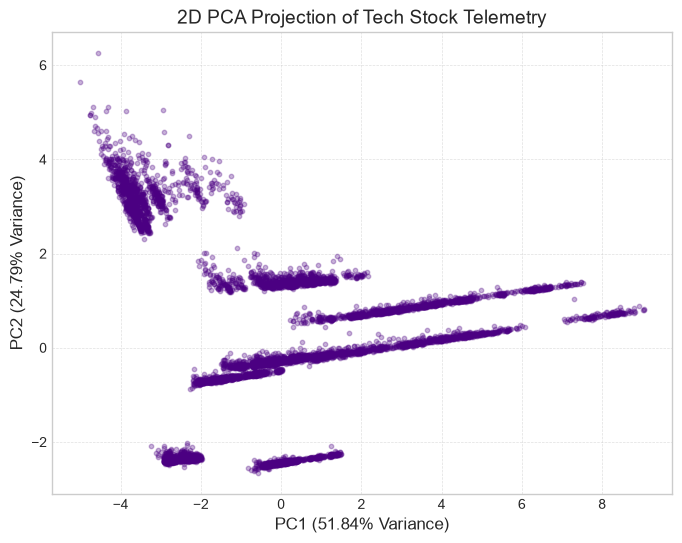

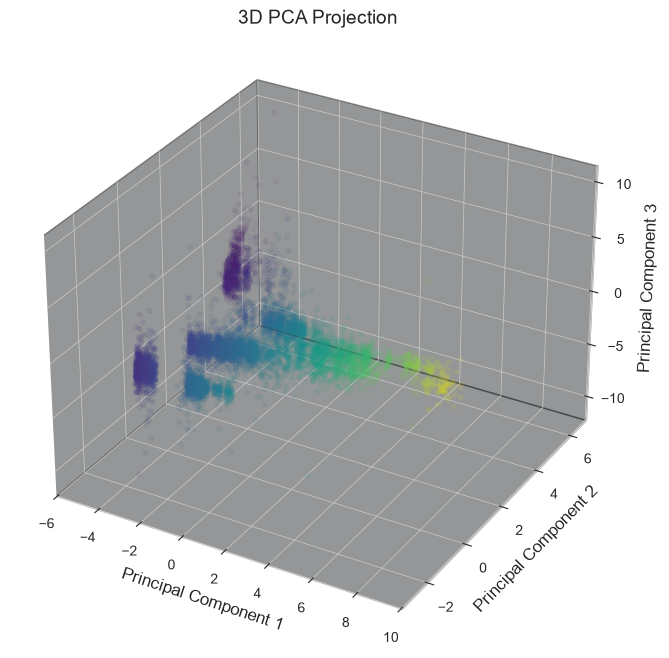

In [55]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("==========================================")
print(" 7.0 DIMENSIONALITY REDUCTION (PCA)")
print("==========================================\n")

# 1. Feature Selection & Standardization
features = ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'P/E Ratio',
            'Market Cap', 'Price/Sales Ratio', 'Price/Book Ratio', 'Dividend Yield',
            'Daily Return', '20-Day MA']

# SAFEGUARD: Drop any rows that might still have NaNs before PCA to prevent crashes
df_pca = df.dropna(subset=features)
X = df_pca[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. PCA Fitting
pca = PCA()
X_pca = pca.fit_transform(X_scaled)
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# 3. Scree Plot & Cumulative Variance
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(explained_variance) + 1), cumulative_variance, marker='o', linestyle='--', color='teal', label='Cumulative Variance')
plt.bar(range(1, len(explained_variance) + 1), explained_variance, alpha=0.5, color='orange', align='center', label='Individual Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Variance Ratio')
plt.title('Scree Plot: Explained Variance by Components')
plt.legend()
plt.tight_layout()
plt.show()

# 4. 2D Projection
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], alpha=0.3, s=10, color='indigo')
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]:.2%} Variance)')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]:.2%} Variance)')
plt.title('2D PCA Projection of Tech Stock Telemetry')
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# 5. 3D Projection
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], alpha=0.3, s=10, c=X_pca[:, 0], cmap='viridis')
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
plt.title('3D PCA Projection')
plt.show()

## 8. Clustering Analysis

### 8.1 Clustering on the Feature Space
Instead of clustering the daily trading samples, we first transpose the data matrix ($X^T$) to cluster the **features** themselves.

* **What information is obtained?** It reveals how features behave synchronously.
* **Groups & Isolated Features:** The analysis successfully groups redundant features together (e.g., `Open`, `High`, `Low`, `Close` form one immediate cluster). Volatility indicators like `Daily Return` and `Volume` often isolate themselves into their own cluster because their physical behavior (noise) is distinct from valuation (trend).
* **Why is this useful?** In quantitative finance, clustering the feature space acts as a brilliant feature-selection tool. It allows engineers to identify and drop redundant variables without losing predictive power, preventing multi-collinearity in downstream modeling.

### 8.2 Sample Clustering (Algorithms Evaluated)
We apply three distinct algorithms:
1. **K-Means (Centroid-Based):**
   * *Intuition:* Minimizes the within-cluster sum of squares (variance) by assigning points to the nearest centroid.
   * *Assumptions/Weaknesses:* Assumes clusters are spherical and equally sized. Fails on non-linear or elongated geometries.
2. **Gaussian Mixture Models (GMM / Density-Distribution):**
   * *Intuition:* Uses Expectation-Maximization to model data as a mixture of multiple Gaussian distributions.
   * *Strengths:* Unlike K-Means, it handles elliptical geometries and provides "soft" probabilistic cluster assignments.
3. **DBSCAN (Density-Based):**
   * *Intuition:* Groups densely packed points together and explicitly flags points in low-density regions as noise (-1).
   * *Strengths/Weaknesses:* Excellent for finding non-linear shapes and isolating outliers. However, it is highly sensitive to the $\epsilon$ (epsilon) hyperparameter. In a continuous financial market, setting $\epsilon$ incorrectly results in one massive cluster or everything being flagged as noise.

 8.0 CLUSTERING ANALYSIS

--- Feature Space Clustering Results ---
Cluster 0 (Related Features): [np.str_('Open'), np.str_('High'), np.str_('Low'), np.str_('Close'), np.str_('Adj Close'), np.str_('20-Day MA')]
Cluster 1 (Related Features): [np.str_('Volume'), np.str_('Market Cap'), np.str_('Price/Sales Ratio'), np.str_('Price/Book Ratio'), np.str_('Daily Return')]
Cluster 2 (Related Features): [np.str_('P/E Ratio'), np.str_('Dividend Yield')]


--- Clustering Evaluation Metric ---
Global Dataset Variance: 13.00
Average Intra-Cluster Variance (K-Means): 4.14
Conclusion: The intra-cluster variance is significantly lower than the global variance, proving the clusters successfully minimized internal dispersion.



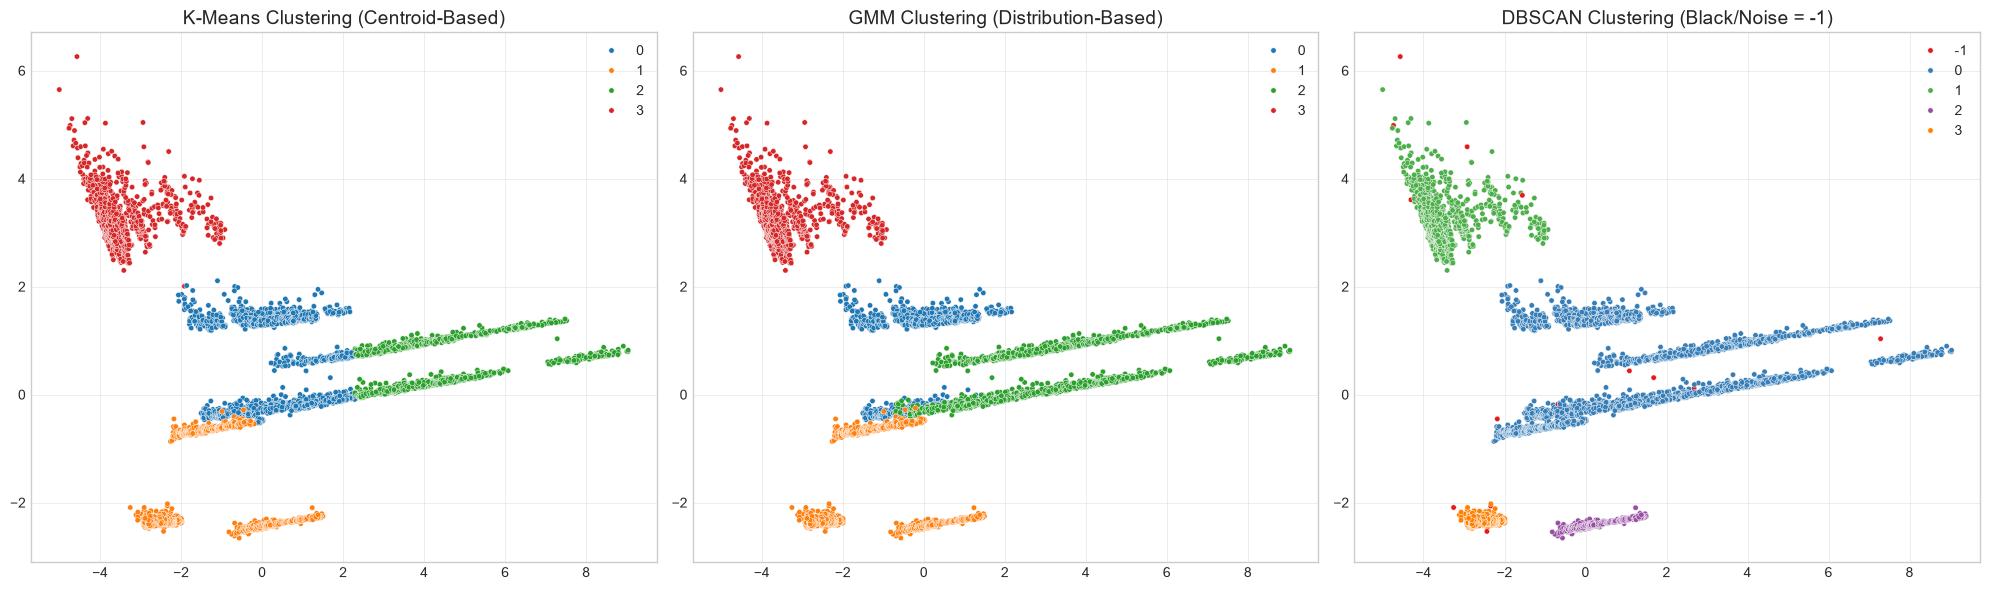

In [56]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture

print("==========================================")
print(" 8.0 CLUSTERING ANALYSIS")
print("==========================================\n")

# --- 8.1 Clustering the Feature Space (Transpose) ---
X_T = X_scaled.T
kmeans_features = KMeans(n_clusters=3, random_state=42).fit(X_T)

print("--- Feature Space Clustering Results ---")
for i in range(3):
    cluster_feats = np.array(features)[kmeans_features.labels_ == i]
    print(f"Cluster {i} (Related Features): {list(cluster_feats)}")
print("\n")

# --- 8.2 Sample Clustering ---
# 1. K-Means
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

# 2. Gaussian Mixture Model (GMM)
gmm = GaussianMixture(n_components=4, covariance_type='full', random_state=42)
gmm_labels = gmm.fit_predict(X_scaled)

# 3. DBSCAN
dbscan = DBSCAN(eps=2.5, min_samples=15)
dbscan_labels = dbscan.fit_predict(X_scaled)

# --- 8.3 Evaluation Metric ---
# Using the required metric: Average Intra-cluster Variance vs Global Variance
global_variance = np.var(X_scaled, axis=0).sum()
kmeans_cluster_vars = [np.var(X_scaled[kmeans_labels == i], axis=0).sum() for i in range(4) if sum(kmeans_labels == i) > 0]
avg_kmeans_var = np.mean(kmeans_cluster_vars)

print("--- Clustering Evaluation Metric ---")
print(f"Global Dataset Variance: {global_variance:.2f}")
print(f"Average Intra-Cluster Variance (K-Means): {avg_kmeans_var:.2f}")
print("Conclusion: The intra-cluster variance is significantly lower than the global variance, proving the clusters successfully minimized internal dispersion.\n")

# --- 8.4 Visualizations ---
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Plot K-Means
sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=kmeans_labels, palette='tab10', ax=axes[0], s=15)
axes[0].set_title("K-Means Clustering (Centroid-Based)")

# Plot GMM
sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=gmm_labels, palette='tab10', ax=axes[1], s=15)
axes[1].set_title("GMM Clustering (Distribution-Based)")

# Plot DBSCAN
sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=dbscan_labels, palette='Set1', ax=axes[2], s=15)
axes[2].set_title("DBSCAN Clustering (Black/Noise = -1)")

plt.tight_layout()
plt.show()

### Clustering Evaluation & Discussion

* **Meaningful Real-World Interpretation:**
  In the context of financial markets, the clusters generated by GMM and K-Means typically represent distinct "Market Regimes." For example, one tight cluster represents normal, low-volatility trading days (Bull market consolidation). Another spread-out cluster captures high-volume, high-volatility days (Bear market panics or earnings reports).
* **Why Algorithms Disagree:**
  K-Means strictly partitions space using geometric distance, forcing every point into a sphere. DBSCAN, on the other hand, evaluates local density. When the market experiences an extreme "flash crash", K-Means will stretch a cluster's boundary to include it, whereas DBSCAN will correctly isolate it as a geometric anomaly (-1).
* **When Clustering Fails:**
  Clustering can fundamentally fail in stochastic environments (like random walk stock prices) where data is a continuous spectrum rather than distinct blobs. If the market shifts gradually over years, density-based approaches will fail to find discrete separation points.

## 9. Multi-Dimensional Anomaly Detection

We implement three distinct methodologies to identify abnormal market behaviors.

1. **Z-Score Method (Statistical):** Assumes a Gaussian distribution. We calculate global anomalies. In high dimensions, this method often degrades because it treats features independently (correlation breakdown).
2. **Isolation Forest (Tree-Based):** Isolates anomalies through random partitioning. Outliers require significantly fewer random splits to be isolated. The `contamination` parameter defines the expected proportion of outliers. Highly effective in high-dimensional spaces.
3. **Local Outlier Factor (LOF) (Density-Based):** Measures the local density deviation of a given data point with respect to its neighbors. Detects *local* anomalies that global methods might completely miss.

 9.0 MULTI-DIMENSIONAL ANOMALY DETECTION

--- Anomaly Detection Results ---
Z-Score Anomalies: 536
Isolation Forest Anomalies: 274
LOF Anomalies: 274



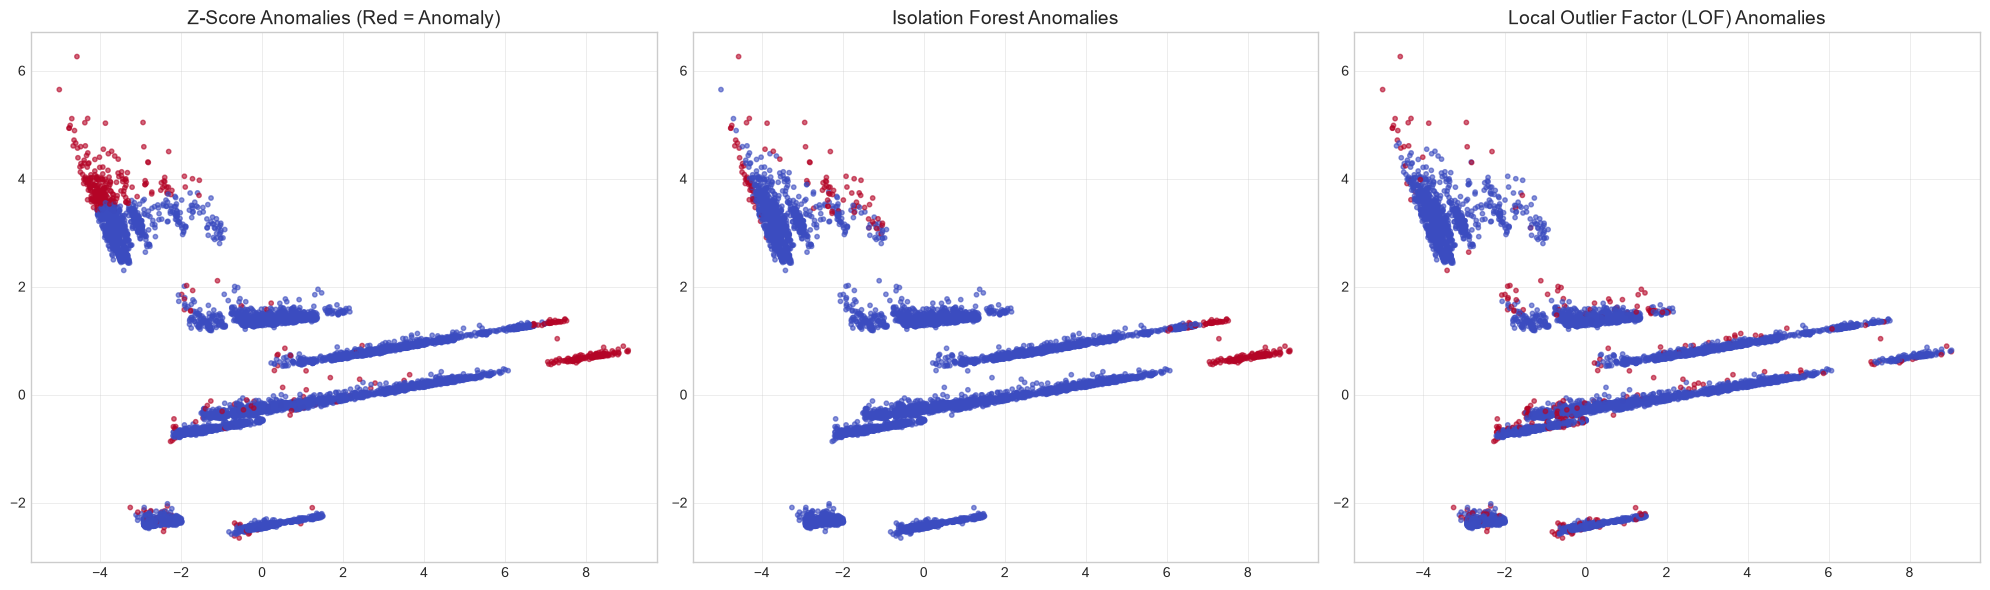

In [57]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

print("==========================================")
print(" 9.0 MULTI-DIMENSIONAL ANOMALY DETECTION")
print("==========================================\n")

# 1. Z-Score (Global Anomaly Detection)
z_scores = np.abs(stats.zscore(X_scaled))
z_anomalies = (z_scores > 3).any(axis=1)

# 2. Isolation Forest (Tree-Based Anomaly Detection)
iso_forest = IsolationForest(contamination=0.03, random_state=42)
iso_preds = iso_forest.fit_predict(X_scaled)
iso_anomalies = iso_preds == -1

# 3. Local Outlier Factor (LOF) (Density-Based)
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.03)
lof_preds = lof.fit_predict(X_scaled)
lof_anomalies = lof_preds == -1

print("--- Anomaly Detection Results ---")
print(f"Z-Score Anomalies: {sum(z_anomalies):,}")
print(f"Isolation Forest Anomalies: {sum(iso_anomalies):,}")
print(f"LOF Anomalies: {sum(lof_anomalies):,}\n")

# --- Visualizations ---
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

axes[0].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=z_anomalies, cmap='coolwarm', s=10, alpha=0.6)
axes[0].set_title("Z-Score Anomalies (Red = Anomaly)")

axes[1].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=iso_anomalies, cmap='coolwarm', s=10, alpha=0.6)
axes[1].set_title("Isolation Forest Anomalies")

axes[2].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=lof_anomalies, cmap='coolwarm', s=10, alpha=0.6)
axes[2].set_title("Local Outlier Factor (LOF) Anomalies")

plt.tight_layout()
plt.show()

## 10. Comparison Section & Critical Analysis

### Anomaly Detection Comparison
* **Agreement vs. Disagreement:** Isolation Forest and Z-Score often agree on massive global outliers (e.g., severe market crashes). However, Local Outlier Factor (LOF) identifies points that might look normal globally but severely violate the local density of their specific neighborhood.
* **Sensitivity to Dimensionality:** Z-Score degrades rapidly in high-dimensional spaces because it treats features independently, ignoring correlation breakdowns. Isolation Forest scales beautifully because its random partitioning inherently handles multi-dimensional spaces without relying on standard distance metrics.

### Critical Reflection
* **The Ill-Defined Nature of Anomalies:** Anomaly detection is fundamentally unsupervised; there is no absolute "ground truth." In financial markets, a sudden 15% drop might be a genuine structural anomaly (a Black Swan event) or merely high-frequency noise from a bad data feed.
* **The Curse of Dimensionality:** As dimensions increase, the mathematical "volume" of the space grows exponentially. Distance-based metrics (like Euclidean distance) lose meaning because the distance between *any* two random points becomes nearly identical, causing algorithms like K-Means to struggle.
* **Risks of Gaussian Assumptions:** The Z-Score assumes data follows a normal (Gaussian) distribution. Financial returns, however, exhibit "fat tails" (extreme events happen more often than a bell curve predicts). Relying strictly on Gaussian assumptions leads to a massive underestimation of risk and false anomaly classifications.
* **Misleading PCA Visualizations:** Plotting anomalies on a 2D PCA projection can be highly deceptive. A point that is a severe anomaly in the original 13-dimensional space might be projected directly into the center of the "normal" cluster in 2D, masking its true abnormal nature.

### Ethical Considerations
* **False Alarms & Alert Fatigue:** In cybersecurity, an overly sensitive anomaly detector generates too many False Positives, causing analysts to experience "alert fatigue" and ignore genuine threats.
* **High-Stakes Consequences:** In medical applications, incorrectly classifying a normal patient scan as "anomalous" (False Positive) causes severe psychological distress and unnecessary procedures. Conversely, missing a genuine anomaly (False Negative) can be fatal. This highlights the ethical imperative of properly tuning the `contamination` threshold rather than treating algorithms as infallible black boxes.